In [62]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("./nb_loan.csv")
df.head(5)

,TID,Refund,Marital_Status,Taxable_Income_K,Evade
0,1,Yes,Single,125,No
1,2,No,Married,100,No
2,3,No,Single,70,No
3,4,Yes,Married,120,No
4,5,No,Divorced,95,Yes


In [3]:
X = df.drop(columns=["TID", "Evade"])
y = df["Evade"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [4]:
prior_prob = y_train.value_counts(normalize=True)
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
yes_data = X_train[y_train=="Yes"]
no_data = X_train[y_train=="No"]

In [52]:
class NaiveBayes:
    def __init__(self, alpha=1):
        self.alpha = alpha

    def fit(self, X, y):
        self.X = X.reset_index(drop=True).copy()
        self.y = y.reset_index(drop=True).copy()

        prior_prob = self.y.value_counts(normalize=True)

        self.yes_data = self.X[self.y == "Yes"]
        self.no_data = self.X[self.y == "No"]

        self.yes_prob = prior_prob["Yes"]
        self.no_prob = prior_prob["No"]

        return self


    def predict(self, X_test):
        results = []
        for _, row in X_test.iterrows():


            refund, marital_status, income = row
    
            
            yes_prob = self.yes_prob
            no_prob = self.no_prob
    
            
            yes_prob *= self.likelihood(
                self.yes_data, "Refund", refund
            )
            yes_prob *= self.likelihood(
                self.yes_data, "Marital_Status", marital_status
            )
            yes_prob *= self.gaussian_likelihood(
                self.yes_data, "Taxable_Income_K", income
            )
    
            
            no_prob *= self.likelihood(
                self.no_data, "Refund", refund
            )
            no_prob *= self.likelihood(
                self.no_data, "Marital_Status", marital_status
            )
            no_prob *= self.gaussian_likelihood(
                self.no_data, "Taxable_Income_K", income
            )
    
            
            total_prob = yes_prob + no_prob

            results.append([yes_prob / total_prob, no_prob / total_prob])
        return np.array(results)

    def gaussian_likelihood(self, data, column, value):
        mean = data[column].mean()
        std = data[column].std()
    
        variance = std ** 2
    
        coefficient = 1 / np.sqrt(2 * np.pi * variance)
    
        exponent = -((value - mean) ** 2) / (2 * variance)

        return coefficient * np.exp(exponent)
        
    def likelihood(self, data, column, value):
        count = (data[column] == value).sum()
        total = len(data)
        K = self.X[column].nunique()

        return (count + self.alpha) / (total + self.alpha * K)

    def predict_class(self, X_test):
        probabilities = self.predict(X_test)
    
        predictions = np.where(
            probabilities[:, 0] > probabilities[:, 1],
            "Yes",
            "No"
        )

        return predictions

In [54]:
nb = NaiveBayes()
nb.fit(X_train, y_train)
y_pred = nb.predict_class(X_test)

In [65]:
from sklearn.metrics import classification_report,confusion_matrix
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

          No       1.00      1.00      1.00         3
         Yes       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



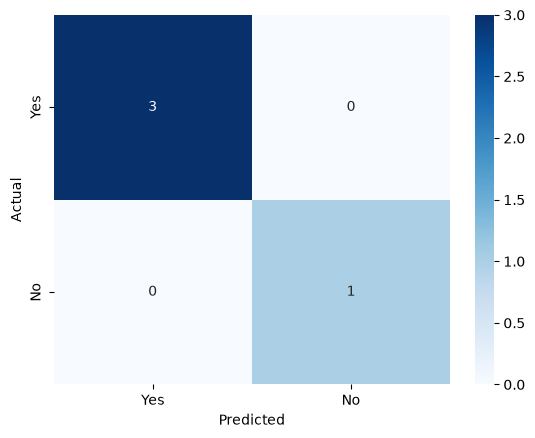

In [64]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Yes", "No"],
    yticklabels=["Yes", "No"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()